# Normal-tissue protein co-representation



The primary score uses one global square-root intensity scale, the minimum of each antigen pair, and a sum over the 24 HPA-DVP cell-type groups. It is an exploratory model, not a safety estimate.

In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt

repository = next(parent for parent in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
                  if (parent / "scripts" / "hpa_liability.py").exists())
if str(repository) not in sys.path:
    sys.path.insert(0, str(repository))

from scripts.publication_figure_state import project_paths
from scripts.hpa_liability import load_hpa, hpa_summaries, export_hpa, draw_hpa

project, repository = project_paths()

In [2]:
import os

data_file = project / "Data" / "dvp_cell_type_group_data.tsv.zip"
df_dir = Path(os.environ.get("CAP_HPA_TABLES", project / "Dataframe_Saves"))
fig_dir = Path(os.environ.get("CAP_HPA_FIGURES", project / "Figures"))

In [3]:
abundance, provenance = load_hpa(data_file)

abundance

Gene name,ROR1,EGFR,ERBB2,EPCAM
Cell type name,,,,
b-cells,NaN,207368.6,NaN,NaN
t-cells,NaN,913336.2,NaN,NaN
macrophages,NaN,785352.9,NaN,NaN
neutrophils,NaN,NaN,NaN,NaN
neurons,NaN,306889.9,NaN,NaN
astrocytes and neuropil,NaN,1670123.7,NaN,NaN
microglia and neuropil,NaN,2542477.8,NaN,NaN
cardiomyocytes,NaN,NaN,NaN,NaN
capillaries,NaN,1138988.2,NaN,NaN


Non-quantified intensities remain missing in the source table and appear as crosses in the figure. They contribute zero only to the declared primary score. Non-detection does not establish absence. HPA pools cells within groups; this does not measure same-cell surface co-display.

Source: [HPA-DVP methods](https://www.proteinatlas.org/humanproteome/single%2Bcell/dvp/method).

In [4]:
results = hpa_summaries(abundance)

results["coverage"]

,n_quantified,n_unquantified,n_groups
Gene name,,,
ROR1,6,18,24
EGFR,21,3,24
ERBB2,13,11,24
EPCAM,11,13,24


In [5]:
results["summary"]

,ctli_sum,ctli_max,top_cell_type,n_joint_quantified,n_groups,joint_quantified_mean,top_share_of_sum,rank
ROR1+ERBB2,0.231649,0.127613,alveolar cell types,5,24,0.046330,0.550891,1
ROR1+EPCAM,0.231649,0.127613,alveolar cell types,5,24,0.046330,0.550891,1
ROR1+EGFR,0.258806,0.127613,alveolar cell types,6,24,0.043134,0.493085,3
ERBB2+EPCAM,1.685624,0.395707,collecting ducts,11,24,0.153239,0.234754,4
EGFR+ERBB2,2.544720,0.395707,collecting ducts,13,24,0.195748,0.155501,5
EGFR+EPCAM,3.013640,0.650129,collecting ducts,11,24,0.273967,0.215729,6


In [6]:
export_hpa(abundance, results, provenance, df_dir)

Sensitivity analyses retain the maximum local score and leave-one-group-out ranking. Linear and log1p transforms use the same global scaling convention. Missing-value scenarios are stress tests, not inferred detection limits or biological imputations. The old Michaelis-constant sensitivity does not apply to this formula.

In [7]:
results["transforms"].pivot(index="pair", columns="transform", values="rank")

transform,linear,log1p,sqrt
pair,,,
EGFR+EPCAM,6.0,5.0,6.0
EGFR+ERBB2,5.0,6.0,5.0
ERBB2+EPCAM,4.0,4.0,4.0
ROR1+EGFR,3.0,3.0,3.0
ROR1+EPCAM,1.0,1.0,1.0
ROR1+ERBB2,1.0,1.0,1.0


In [8]:
results["leave_one_out"].groupby("pair")["rank"].agg(["min", "max"])

,min,max
pair,,
EGFR+EPCAM,6.0,6.0
EGFR+ERBB2,5.0,5.0
ERBB2+EPCAM,4.0,4.0
ROR1+EGFR,1.0,3.0
ROR1+EPCAM,1.0,1.0
ROR1+ERBB2,1.0,1.0


In [9]:
results["missing_scenarios"].pivot(index="pair", columns="scenario", values="rank")

scenario,pooled detected median,pooled detected q10,zero contribution
pair,,,
EGFR+EPCAM,6.0,6.0,6.0
EGFR+ERBB2,5.0,5.0,5.0
ERBB2+EPCAM,4.0,4.0,4.0
ROR1+EGFR,2.0,2.0,3.0
ROR1+EPCAM,1.0,1.0,1.0
ROR1+ERBB2,3.0,2.0,1.0


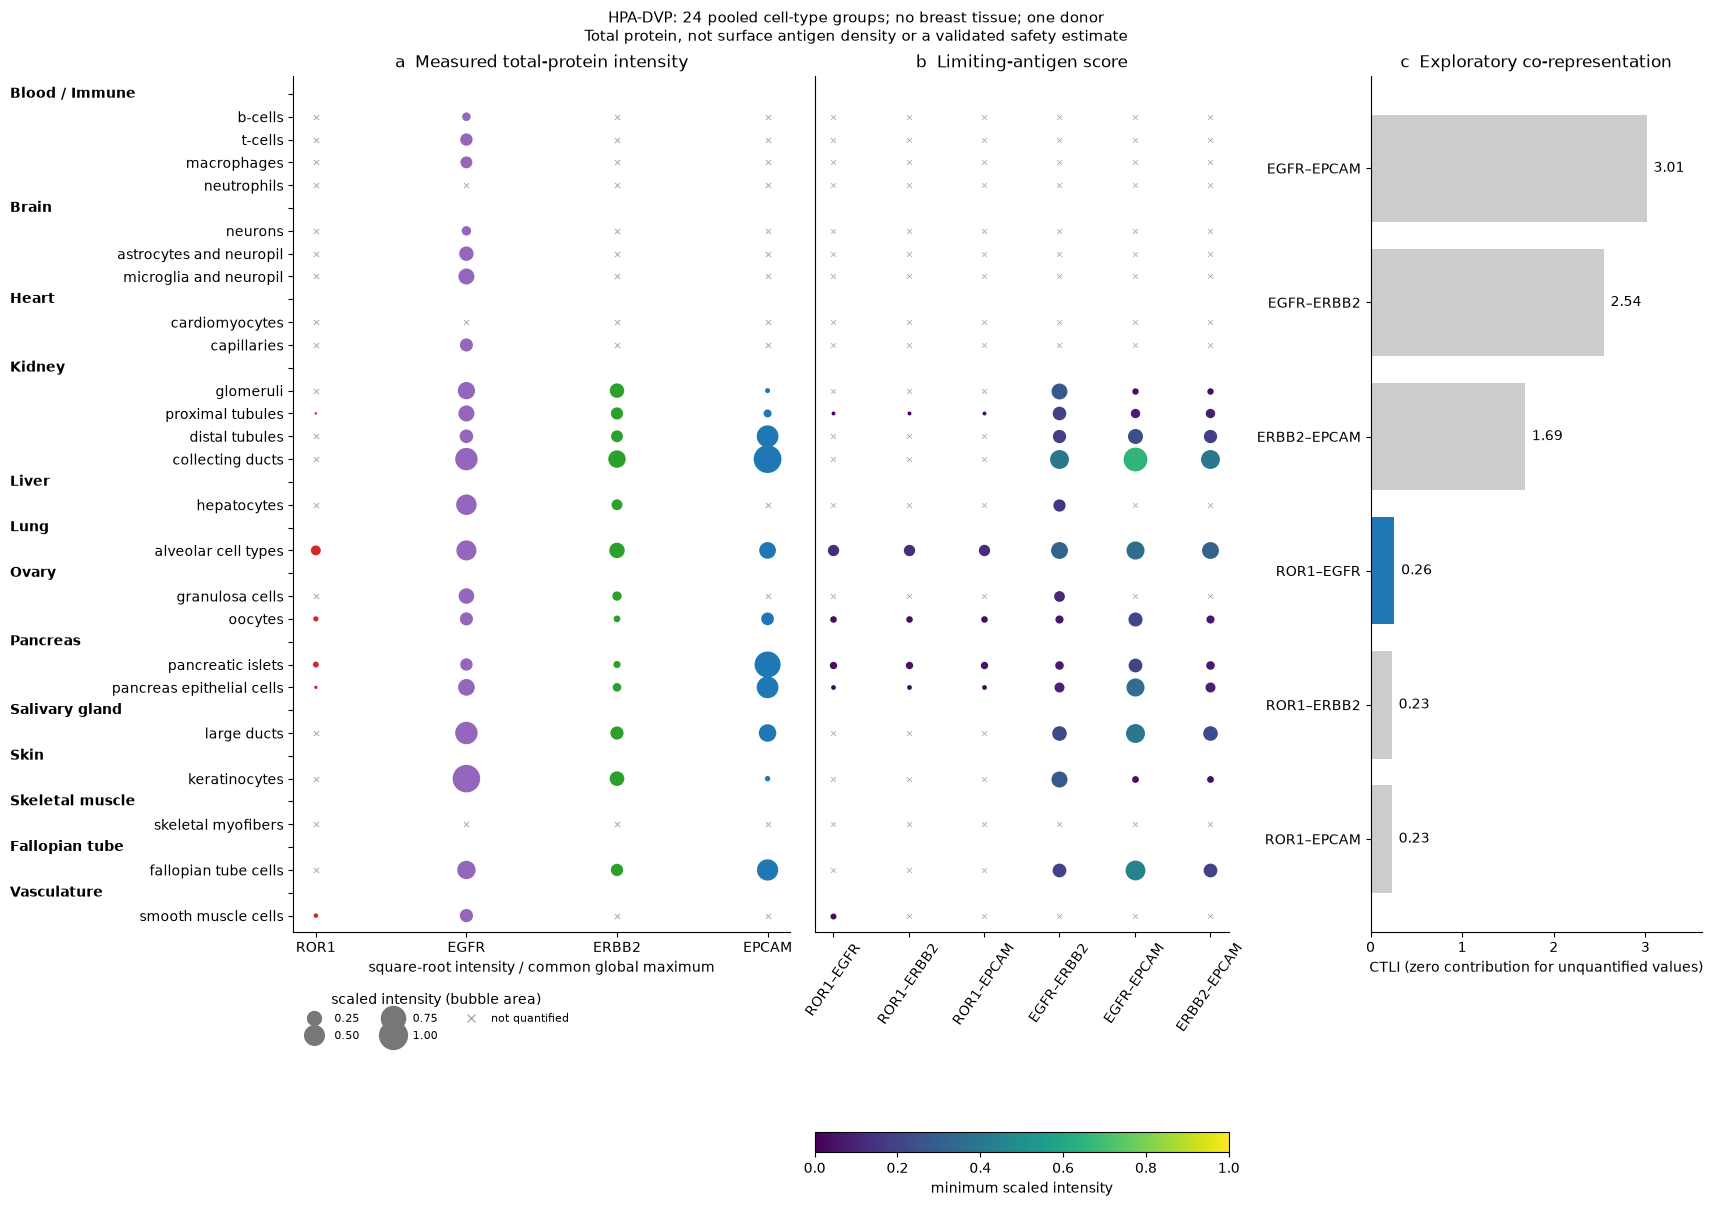

In [10]:
figure = draw_hpa(abundance, results, fig_dir)

HPA-DVP contains no breast tissue and profiles a limited panel from one donor. These results cannot establish normal-breast liability, accessible surface density or clinical safety. Raw intensities from different proteins are not calibrated molecule counts. The archive checksum is recorded; its release and retrieval date still require confirmation before deposit.

In [11]:
import session_info

session_info.show()

/opt/miniconda3/envs/cap/lib/python3.11/site-packages/session_info/main.py:213: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('scanpy')` instead
  mod_version = _find_version(mod.__version__)
/opt/miniconda3/envs/cap/lib/python3.11/site-packages/session_info/main.py:213: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('anndata')` instead.
  mod_version = _find_version(mod.__version__)
